In [1]:
import sys
from pathlib import Path

print("Python:", sys.executable)
print("Working directory:", Path.cwd())

Python: C:\Users\ch_mi\anaconda3\python.exe
Working directory: C:\Users\ch_mi\PycharmProjects\pythonProject\macroeconomic-regimes-portfolio-analysis


# 01 — Macroeconomic Data Cleaning

## Consumer Price Index (CPI)

**Source:** Federal Reserve Economic Data (FRED)

**Series:** CPIAUCSL

**Research period:** 2008–2025

### Objective
Inspect, validate and prepare monthly CPI data
for macroeconomic analysis.

In [2]:

import pandas as pd
from pathlib import Path

# Load raw CPI dataset
file_path = Path("data/raw/CPIAUCSL.csv")

cpi = pd.read_csv(file_path, parse_dates=["observation_date"])

# Initial inspection
display(cpi.head())
print("Shape:", cpi.shape)
print("\nData Types:")
print(cpi.dtypes)
print("\nMissing Values:")
print(cpi.isnull().sum())
print("\nDuplicate Dates:", cpi["observation_date"].duplicated().sum())


,observation_date,CPIAUCSL
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95


Shape: (957, 2)

Data Types:
observation_date    datetime64[ns]
CPIAUCSL                   float64
dtype: object

Missing Values:
observation_date    0
CPIAUCSL            1
dtype: int64

Duplicate Dates: 0


In [3]:
# Select the research period
cpi_filtered = cpi[
    (cpi["observation_date"] >= "2007-01-01") &
    (cpi["observation_date"] <= "2025-12-01")
].copy()

cpi_filtered = cpi_filtered.sort_values(
    "observation_date"
).reset_index(drop=True)

print("Dataset shape:", cpi_filtered.shape)

print("\nFirst observations:")
display(cpi_filtered.head())

print("\nLast observations:")
display(cpi_filtered.tail())

print("\nMissing CPI observations:")
display(cpi_filtered[cpi_filtered["CPIAUCSL"].isna()])

Dataset shape: (228, 2)

First observations:


,observation_date,CPIAUCSL
0,2007-01-01,203.437
1,2007-02-01,204.226
2,2007-03-01,205.288
3,2007-04-01,205.904
4,2007-05-01,206.755



Last observations:


,observation_date,CPIAUCSL
223,2025-08-01,323.291
224,2025-09-01,324.245
225,2025-10-01,NaN
226,2025-11-01,325.063
227,2025-12-01,326.031



Missing CPI observations:


,observation_date,CPIAUCSL
225,2025-10-01,NaN


In [4]:

# Calculate Year-over-Year inflation
cpi_filtered["inflation_yoy"] = (
    cpi_filtered["CPIAUCSL"]
    .pct_change(periods=12, fill_method=None)
    * 100
)

# Keep the research period 2008–2025
inflation = cpi_filtered[
    cpi_filtered["observation_date"] >= "2008-01-01"
].copy()

display(inflation.head())
display(inflation.tail())

print("Valid inflation observations:",
      inflation["inflation_yoy"].count())

print("Missing inflation observations:",
      inflation["inflation_yoy"].isna().sum())


,observation_date,CPIAUCSL,inflation_yoy
12,2008-01-01,212.174,4.294696
13,2008-02-01,212.687,4.142959
14,2008-03-01,213.448,3.974904
15,2008-04-01,213.942,3.903761
16,2008-05-01,215.208,4.088414


,observation_date,CPIAUCSL,inflation_yoy
223,2025-08-01,323.291,2.938592
224,2025-09-01,324.245,3.022572
225,2025-10-01,NaN,NaN
226,2025-11-01,325.063,2.696444
227,2025-12-01,326.031,2.653304


Valid inflation observations: 215
Missing inflation observations: 1


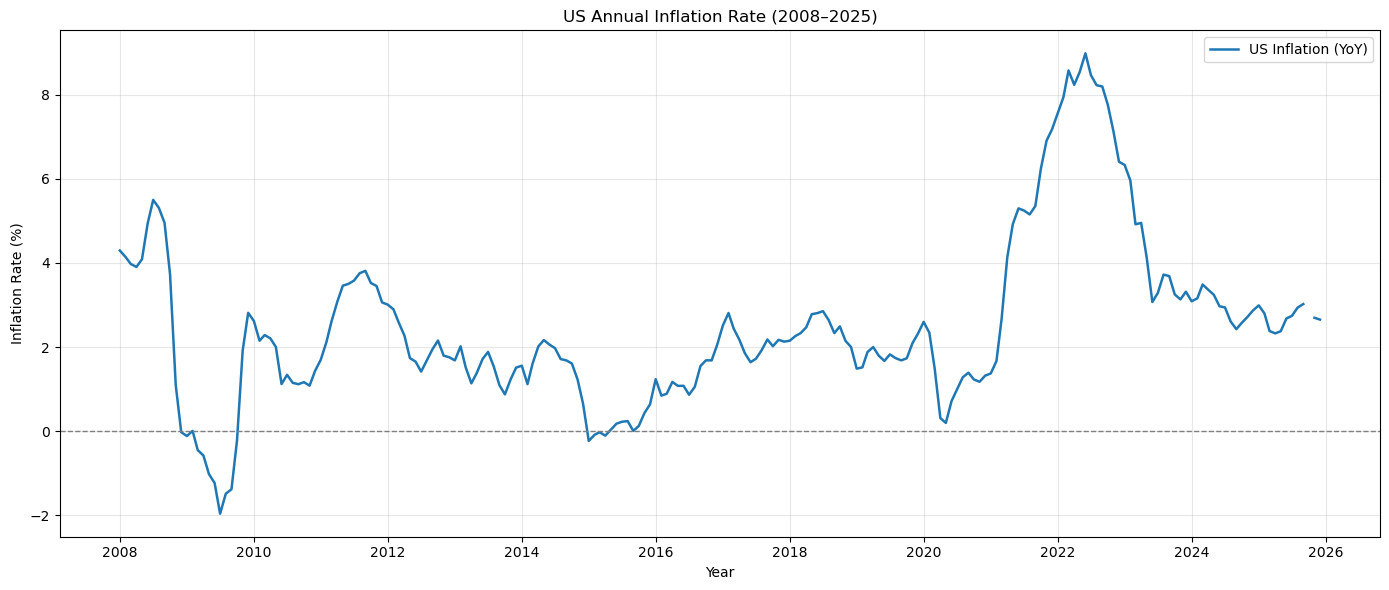

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    inflation["observation_date"],
    inflation["inflation_yoy"],
    linewidth=1.8,
    label="US Inflation (YoY)"
)

plt.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title("US Annual Inflation Rate (2008–2025)")
plt.xlabel("Year")
plt.ylabel("Inflation Rate (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


In [6]:

from pathlib import Path

# Define output directory
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned inflation dataset
inflation.to_csv(
    output_dir / "us_inflation_2008_2025.csv",
    index=False
)

print("Dataset saved successfully!")
print("Shape:", inflation.shape)


Dataset saved successfully!
Shape: (216, 3)
